In [40]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

# --- 1. Importation des fichiers ---
data1 = pd.read_csv("Données SPY.csv")
data2 = pd.read_csv("AAPL.csv")
data3 = pd.read_csv("USD_CNY.csv")
data4 = pd.read_csv("DTB6 (1).csv")
data5 = pd.read_csv("HIS.csv")
data6 = pd.read_csv("Gold.csv")
data7 = pd.read_csv("TCD6.csv")
data8 = pd.read_csv("DR5.xls")
data9 = pd.read_csv("Taux_ST6.xls")
data10 = pd.read_csv("VRV.xls")

# --- 2. Uniformisation des colonnes et conversion de la date ---
for df in [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]:
    df.columns = [col.strip().capitalize() for col in df.columns]
    if 'Unnamed: 0' in df.columns:
        df.rename(columns={'Unnamed: 0':'Date'}, inplace=True)
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# --- 3. Calcul des rendements avant fusion (corrigé) ---
# Nettoyage spécifique pour le fichier HIS
data5['Price'] = data5['Price'].astype(str)
data5['Price'] = data5['Price'].str.replace(',', '', regex=False)  # supprimer les virgules
data5['Price'] = pd.to_numeric(data5['Price'], errors='coerce')

col_names = ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M', 'DR5', 'Taux_ST6', 'VRV']
col_prices = ['Price','Price','Price','Dtb6','Price','Price','Dcd6m','Price', 'Price', 'Price']
dataframes = [data1, data2, data3, data4, data5, data6, data7, data8, data9, data10]

for df, name, price in zip(dataframes, col_names, col_prices):
    if price in df.columns:
        # Convertir la colonne en numérique avant le calcul
        df[price] = pd.to_numeric(df[price], errors='coerce')
        # Calcul du rendement journalier (en proportion, pas en %)
        df[name] = df[price].pct_change()
        # Supprimer les premières lignes NaN
        df.dropna(subset=[name], inplace=True)

# --- 4. Fusion des fichiers sur la colonne Date avec outer join ---
# On part du SPY (déjà converti en rendement)
data_merged = data1[['Date','SPY']]

# Liste des fichiers restants à fusionner
dfs = [data2, data3, data4, data5, data6, data7, data8, data9, data10]
col_names = ['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]
col_prices = ['AAPL','DollarYuan','DTB6','Price','Or','DCD6M','Dr5', 'St6', 'Vrv']  #  on fusionne sur les rendements déjà calculés

for df, col_name, price_col in zip(dfs, col_names, col_prices):
    data_merged = data_merged.merge(df[['Date', price_col]], on='Date', how='outer')
    data_merged.rename(columns={price_col: col_name}, inplace=True)

print("Nombre de lignes après fusion :", len(data_merged))

# --- 5. Remplissage des valeurs manquantes ---
data_merged.fillna(method='ffill', inplace=True)
data_merged.fillna(method='bfill', inplace=True)
for col in ['SPY','AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV' ]:
    data_merged[col] = pd.to_numeric(data_merged[col], errors='coerce')
    if data_merged[col].isna().sum() > 0:
        data_merged[col].fillna(data_merged[col].mean(), inplace=True)

# --- 6. Supprimer les colonnes trop vides (>50% NaN) ---
X_multi = data_merged[['AAPL','DollarYuan','DTB6','HIS','Or','DCD6M','DR5', 'Taux_ST6', 'VRV']]
X_multi = X_multi.loc[:, X_multi.isna().mean() < 0.5]
y = data_merged[['SPY']]

# Nettoyage final : supprimer les lignes restantes avec NaN
data_clean = pd.concat([X_multi, y], axis=1).dropna()
X_multi = data_clean.drop(columns=['SPY'])
y = data_clean[['SPY']]

print("Lignes finales après nettoyage :", len(data_clean))
print("Colonnes finales :", X_multi.columns.tolist())

# --- 7. Régression multiple ---
X_multi_sm = sm.add_constant(X_multi)
mon_modele = sm.OLS(y, X_multi_sm).fit()
print(mon_modele.summary())

Nombre de lignes après fusion : 1305
Lignes finales après nettoyage : 1305
Colonnes finales : ['AAPL', 'DollarYuan', 'DTB6', 'HIS', 'Or', 'DCD6M', 'DR5', 'Taux_ST6', 'VRV']
                            OLS Regression Results                            
Dep. Variable:                    SPY   R-squared:                       0.241
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     45.75
Date:                Fri, 10 Oct 2025   Prob (F-statistic):           9.74e-72
Time:                        18:16:37   Log-Likelihood:                 3805.2
No. Observations:                1305   AIC:                            -7590.
Df Residuals:                    1295   BIC:                            -7539.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err     

In [41]:
from statsmodels.stats.diagnostic import linear_rainbow, linear_reset

# Test de Rainbow sur le modèle 
rainbow_stat, p_value = linear_rainbow(mon_modele)

print("Statistique Rainbow:", rainbow_stat)
print("p-value:", p_value)

Statistique Rainbow: 1.3044433259933195
p-value: 0.00036898394232681383


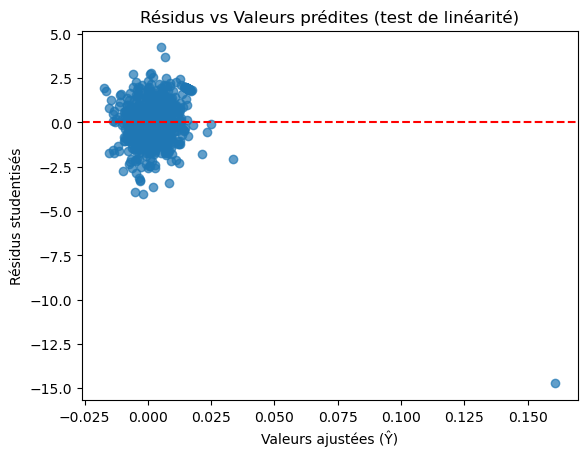

In [42]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Extraction des résidus studentisés
influence = mon_modele.get_influence()
resid_student = influence.resid_studentized_internal
fitted_vals = mon_modele.fittedvalues

# Graphique
plt.scatter(fitted_vals, resid_student, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Valeurs ajustées (Ŷ)")
plt.ylabel("Résidus studentisés")
plt.title("Résidus vs Valeurs prédites (test de linéarité)")
plt.show()

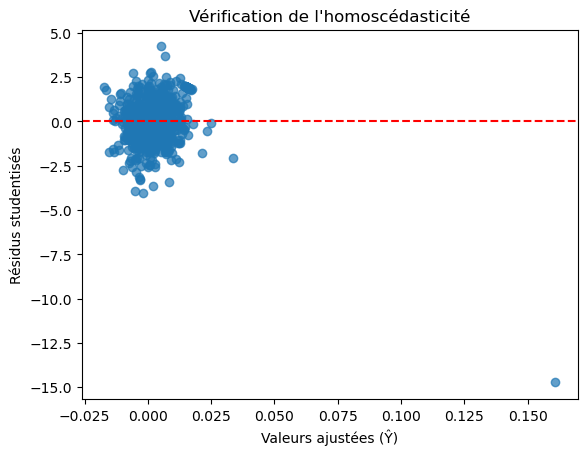

In [43]:
plt.scatter(fitted_vals, resid_student, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Valeurs ajustées (Ŷ)")
plt.ylabel("Résidus studentisés")
plt.title("Vérification de l'homoscédasticité")
plt.show()

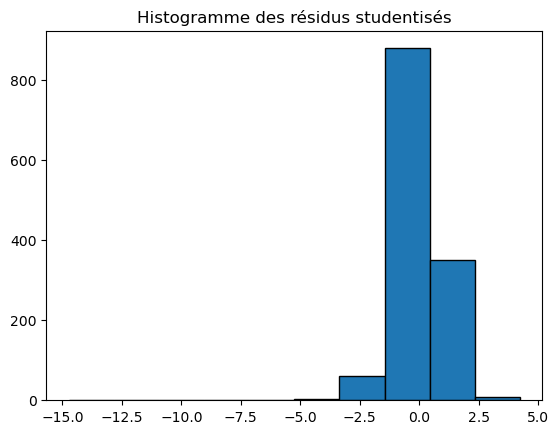

In [44]:
import matplotlib.pyplot as plt

plt.hist(resid_student, bins=10, edgecolor='k')
plt.title("Histogramme des résidus studentisés")
plt.show()

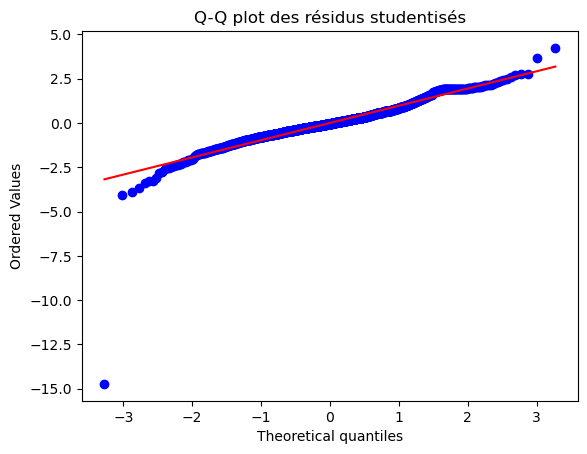

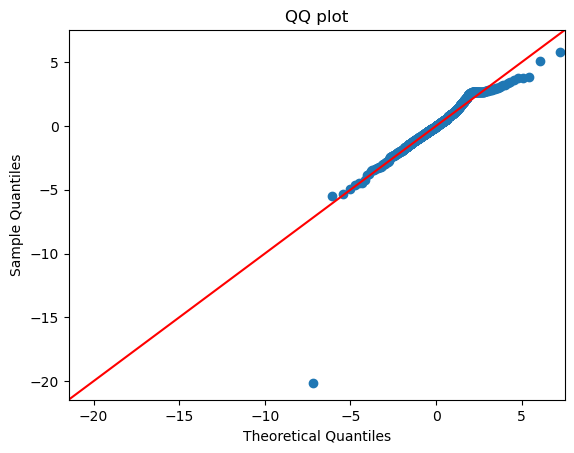

In [45]:
import scipy.stats as stats

stats.probplot(resid_student, dist="norm", plot=plt)
plt.title("Q-Q plot des résidus studentisés")
plt.show()
# ou alors
fig = sm.qqplot(resid_student, stats.t, fit=True,line='45')
plt.title("QQ plot")
plt.show()

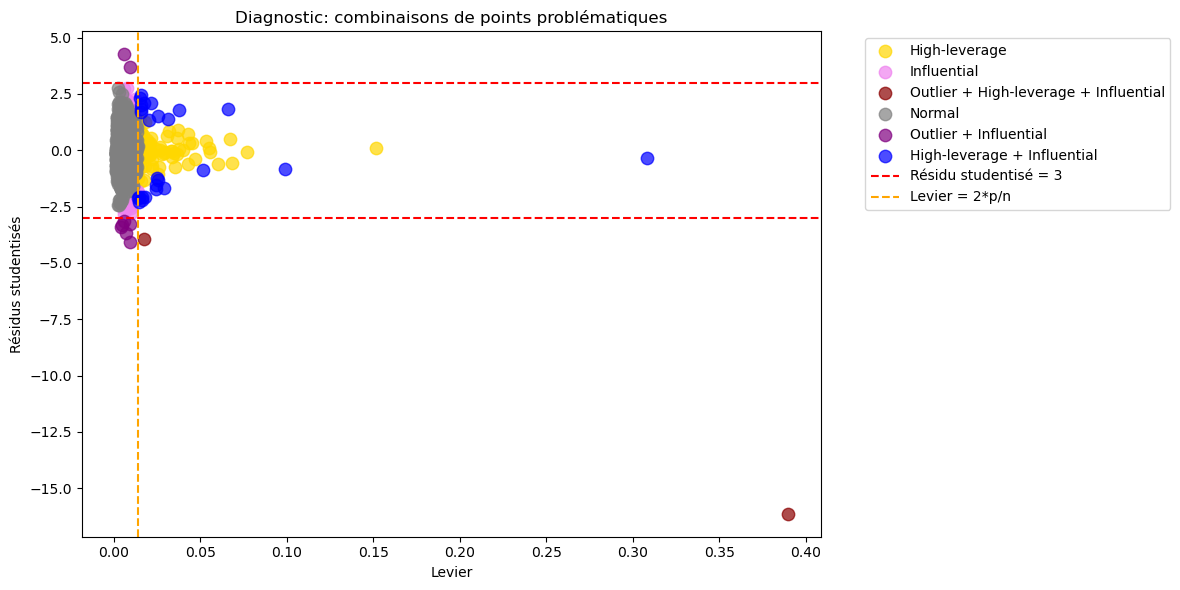

In [46]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np


influence = mon_modele.get_influence()
summary_frame = influence.summary_frame()

# Mesures
resid_student = influence.resid_studentized_external
leverage = summary_frame['hat_diag']
cooks_d = summary_frame['cooks_d']

# Seuils
n, p = X_multi.shape
outlier_threshold = 3
leverage_threshold = 2 * p / n
cooks_threshold = 4 / n

# Détection des catégories
is_outlier = abs(resid_student) > outlier_threshold
is_high_lev = leverage > leverage_threshold
is_influential = cooks_d > cooks_threshold

# Attribution des couleurs selon combinaisons
colors = []
labels = []

for o, h, i in zip(is_outlier, is_high_lev, is_influential):
    if o and h and i:
        colors.append('darkred')
        labels.append('Outlier + High-leverage + Influential')
    elif o and h:
        colors.append('orange')
        labels.append('Outlier + High-leverage')
    elif o and i:
        colors.append('purple')
        labels.append('Outlier + Influential')
    elif h and i:
        colors.append('blue')
        labels.append('High-leverage + Influential')
    elif o:
        colors.append('red')
        labels.append('Outlier')
    elif h:
        colors.append('gold')
        labels.append('High-leverage')
    elif i:
        colors.append('violet')
        labels.append('Influential')
    else:
        colors.append('gray')
        labels.append('Normal')

# Graphique
plt.figure(figsize=(12,6))
for c, lbl in set(zip(colors, labels)):
    idx = [j for j, l in enumerate(labels) if l == lbl]
    plt.scatter(leverage[idx], resid_student[idx], c=c, s=80, alpha=0.7, label=lbl)

plt.axhline(y=outlier_threshold, color='red', linestyle='--', label='Résidu studentisé = 3')
plt.axhline(y=-outlier_threshold, color='red', linestyle='--')
plt.axvline(x=leverage_threshold, color='orange', linestyle='--', label='Levier = 2*p/n')
plt.xlabel("Levier")
plt.ylabel("Résidus studentisés")
plt.title("Diagnostic: combinaisons de points problématiques")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()



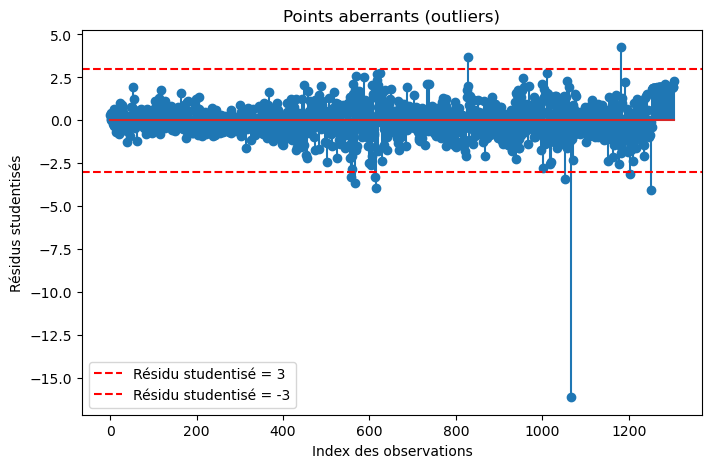

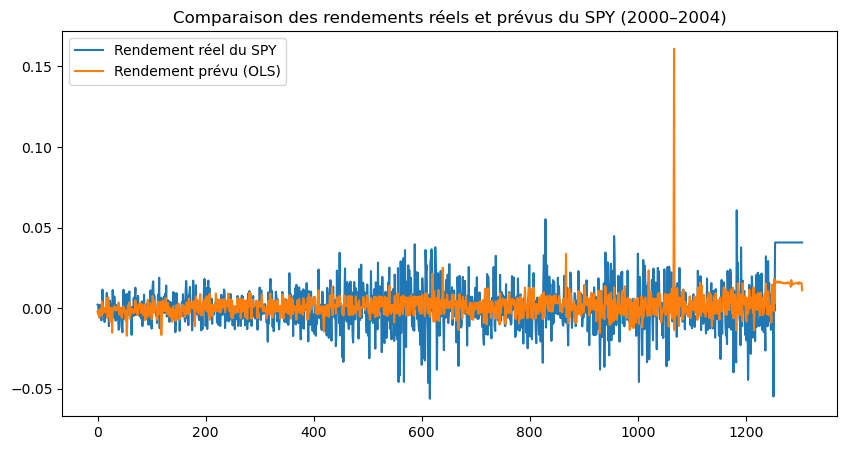

In [51]:
#Analyse des points aberrants
# Influence et résidus studentisés
influence = mon_modele.get_influence()
summary_frame = influence.summary_frame()
resid_studentise = influence.resid_studentized_external

# Détection des outliers
outliers = resid_studentise[abs(resid_studentise) > 3]

# Graphique
plt.figure(figsize=(8,5))
plt.stem(resid_studentise)
plt.axhline(y=3, color='red', linestyle='--', label='Résidu studentisé = 3')
plt.axhline(y=-3, color='red', linestyle='--', label='Résidu studentisé = -3')
plt.xlabel("Index des observations")
plt.ylabel("Résidus studentisés")
plt.title("Points aberrants (outliers)")
plt.legend()
plt.show()

# les points au-dessus des lignes rouges sont considérés comme outliers.
# ils peuvent indiquer des erreurs de saisie, des valeurs extrêmes ou des cas particuliers du phénomène étudié.
# il est conseillé de les examiner avant toute décision de suppression.

y_pred = mon_modele.predict(X_multi_sm)

plt.figure(figsize=(10,5))
plt.plot(y.values, label="Rendement réel du SPY")
plt.plot(y_pred.values, label="Rendement prévu (OLS)")
plt.title("Comparaison des rendements réels et prévus du SPY (2000–2004)")
plt.legend()
plt.show()


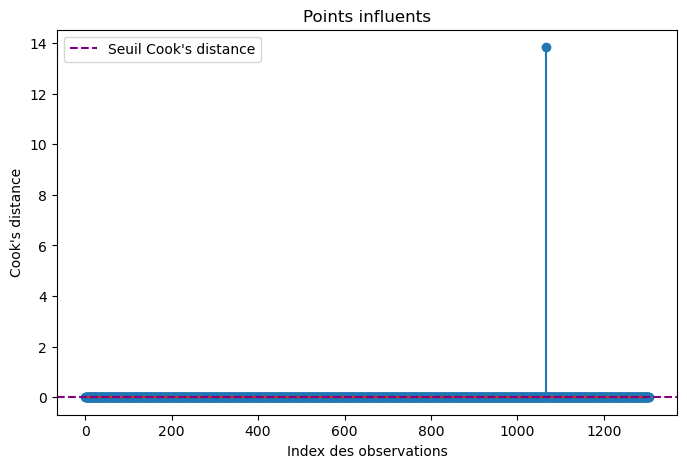

In [48]:
#Points influents
# Critère : Cook's distance > 4/n

cooks_d = summary_frame['cooks_d']
influential_points = cooks_d[cooks_d > 4 / X_multi.shape[0]]

# Graphique
plt.figure(figsize=(8,5))
plt.stem(cooks_d)
plt.axhline(y=4/X_multi.shape[0], color='purple', linestyle='--', label="Seuil Cook's distance")
plt.xlabel("Index des observations")
plt.ylabel("Cook's distance")
plt.title("Points influents")
plt.legend()
plt.show()

# les points au-dessus de la ligne violette sont influents : ils combinent un fort levier et un grand résidu.
# leur suppression ou modification peut changer significativement les coefficients du modèle.
# ils nécessitent un examen poussé pour décider s’ils reflètent une réalité ou une anomalie.

In [49]:
#VIF
# Calcul du VIF pour chaque variable
X_vif = X_multi.copy()  

# Calcul du VIF pour chaque variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print(vif_data)

     Variable       VIF
0        AAPL  1.021655
1  DollarYuan  1.002152
2        DTB6  1.154037
3         HIS  7.193274
4          Or  6.087124
5       DCD6M  1.139865
6         DR5  1.026317
7    Taux_ST6  1.585875
8         VRV  1.044028
